In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image

In [2]:
MODEL_PATH = "../Saved_Models/best_model_finetuned.keras"

model = load_model(MODEL_PATH)

print("Model je učitan.")
print("Broj slojeva:", len(model.layers))

Model je učitan.
Broj slojeva: 244


In [3]:
for layer in reversed(model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        print("Zadnji konvolucijski sloj:", layer.name)
        break

Zadnji konvolucijski sloj: top_conv


In [4]:
class_names = [
    "Mild_DR",
    "Moderate_DR",
    "No_DR",
    "Proliferate_DR",
    "Severe_DR"
]

In [5]:
IMG_SIZE = (224, 224)

def load_image_for_model(img_path):
    img = tf.keras.utils.load_img(
        img_path,
        target_size=IMG_SIZE
    )

    img_array = tf.keras.utils.img_to_array(img)

    # Dodavanje batch dimenzije:
    # (224, 224, 3) -> (1, 224, 224, 3)
    img_batch = np.expand_dims(img_array, axis=0)

    return img_array, img_batch

In [6]:
def make_gradcam_heatmap(
    img_batch,
    model,
    last_conv_layer_name="top_conv",
    pred_index=None
):
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(
            [img_batch],
            training=False
        )

        if pred_index is None:
            pred_index = tf.argmax(predictions[0])

        class_score = predictions[:, pred_index]

    gradients = tape.gradient(
        class_score,
        conv_outputs
    )

    # Prosječan utjecaj svakog kanala
    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients,
        axis=-1
    )

    # Zadržavaju se pozitivni doprinosi
    heatmap = tf.maximum(heatmap, 0)

    max_value = tf.reduce_max(heatmap)

    # Zaštita od dijeljenja s nulom
    heatmap = tf.where(
        max_value > 0,
        heatmap / max_value,
        heatmap
    )

    return heatmap.numpy(), predictions.numpy(), int(pred_index)

In [7]:
def display_gradcam(
    original_img,
    heatmap,
    predicted_class,
    confidence,
    alpha=0.4
):
    original_uint8 = np.clip(
        original_img,
        0,
        255
    ).astype(np.uint8)

    heatmap_resized = cv2.resize(
        heatmap,
        (
            original_uint8.shape[1],
            original_uint8.shape[0]
        )
    )

    heatmap_uint8 = np.uint8(
        255 * heatmap_resized
    )

    heatmap_colored = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    # OpenCV koristi BGR, matplotlib RGB
    heatmap_colored = cv2.cvtColor(
        heatmap_colored,
        cv2.COLOR_BGR2RGB
    )

    superimposed_img = cv2.addWeighted(
        original_uint8,
        1 - alpha,
        heatmap_colored,
        alpha,
        0
    )

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(original_uint8)
    plt.title("Izvorna slika")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title("Grad-CAM toplinska mapa")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(superimposed_img)
    plt.title(
        f"Predikcija: {predicted_class}\n"
        f"Pouzdanost: {confidence:.2%}"
    )
    plt.axis("off")

    plt.tight_layout()
    plt.show()

In [8]:
TEST_PATH = "../Dataset"
SELECTED_CLASS = "Moderate_DR"

class_folder = os.path.join(
    TEST_PATH,
    SELECTED_CLASS
)

image_files = [
    file_name
    for file_name in os.listdir(class_folder)
    if file_name.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
]

IMAGE_PATH = os.path.join(
    class_folder,
    image_files[0]
)

print("Odabrana slika:", IMAGE_PATH)

Odabrana slika: ../Dataset\Moderate_DR\000c1434d8d7.png


In [9]:
original_img, img_batch = load_image_for_model(
    IMAGE_PATH
)

heatmap, predictions, predicted_index = (
    make_gradcam_heatmap(
        img_batch=img_batch,
        model=model,
        last_conv_layer_name="top_conv"
    )
)

predicted_class = class_names[predicted_index]
confidence = predictions[0][predicted_index]

print("Predviđena klasa:", predicted_class)
print("Pouzdanost:", confidence)

print("\nVjerojatnosti svih klasa:")

for class_name, probability in zip(
    class_names,
    predictions[0]
):
    print(
        f"{class_name:16s}: "
        f"{probability:.4f}"
    )

Predviđena klasa: Moderate_DR
Pouzdanost: 0.46577844

Vjerojatnosti svih klasa:
Mild_DR         : 0.2983
Moderate_DR     : 0.4658
No_DR           : 0.0089
Proliferate_DR  : 0.2158
Severe_DR       : 0.0113


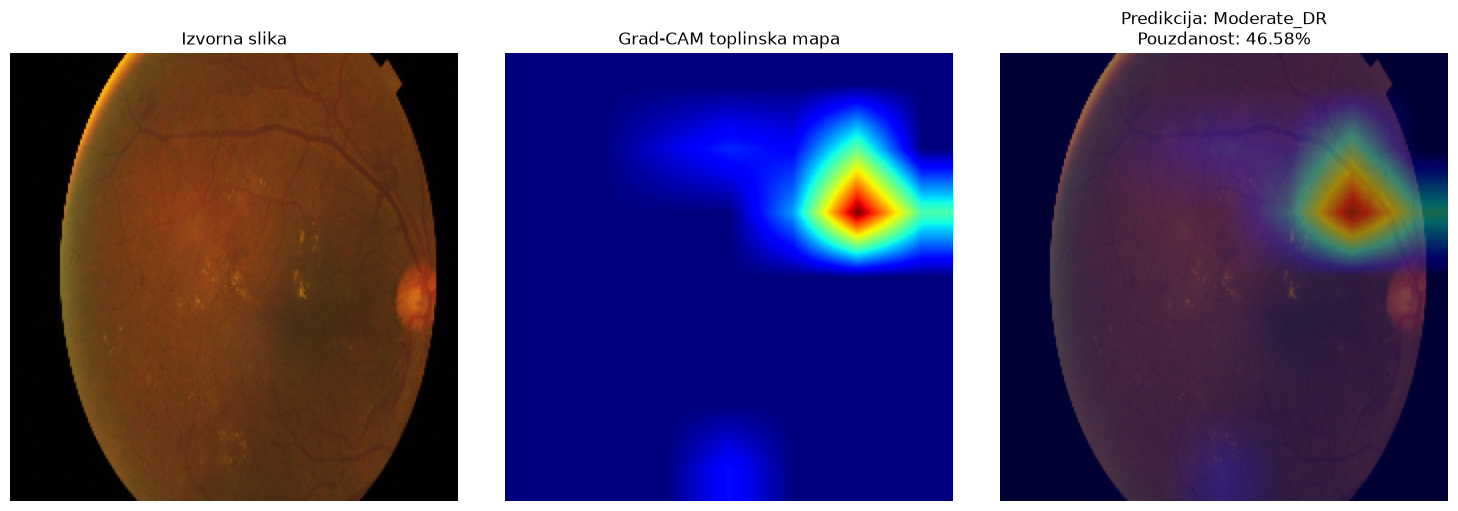

In [10]:
display_gradcam(
    original_img=original_img,
    heatmap=heatmap,
    predicted_class=predicted_class,
    confidence=confidence
)

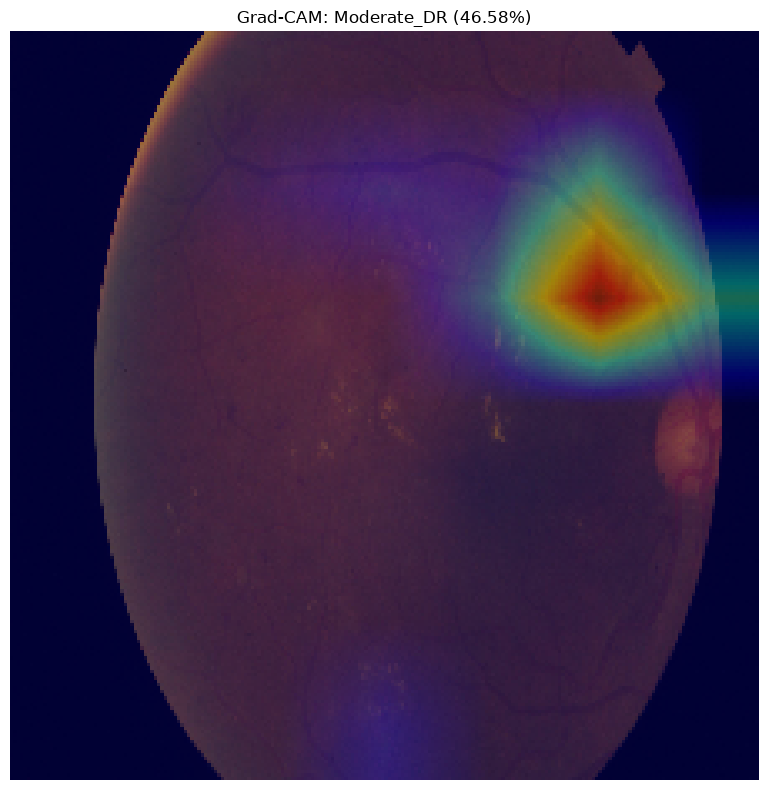

Slika spremljena u: ../Results/GradCAM\gradcam_moderate_dr.png


In [11]:
OUTPUT_DIR = "../Results/GradCAM"
os.makedirs(OUTPUT_DIR, exist_ok=True)

output_path = os.path.join(
    OUTPUT_DIR,
    "gradcam_moderate_dr.png"
)

original_uint8 = np.clip(
    original_img,
    0,
    255
).astype(np.uint8)

heatmap_resized = cv2.resize(
    heatmap,
    (
        original_uint8.shape[1],
        original_uint8.shape[0]
    )
)

heatmap_uint8 = np.uint8(
    255 * heatmap_resized
)

heatmap_colored = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

heatmap_colored = cv2.cvtColor(
    heatmap_colored,
    cv2.COLOR_BGR2RGB
)

superimposed_img = cv2.addWeighted(
    original_uint8,
    0.6,
    heatmap_colored,
    0.4,
    0
)

plt.figure(figsize=(8, 8))
plt.imshow(superimposed_img)
plt.title(
    f"Grad-CAM: {predicted_class} "
    f"({confidence:.2%})"
)
plt.axis("off")
plt.tight_layout()
plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Slika spremljena u:", output_path)

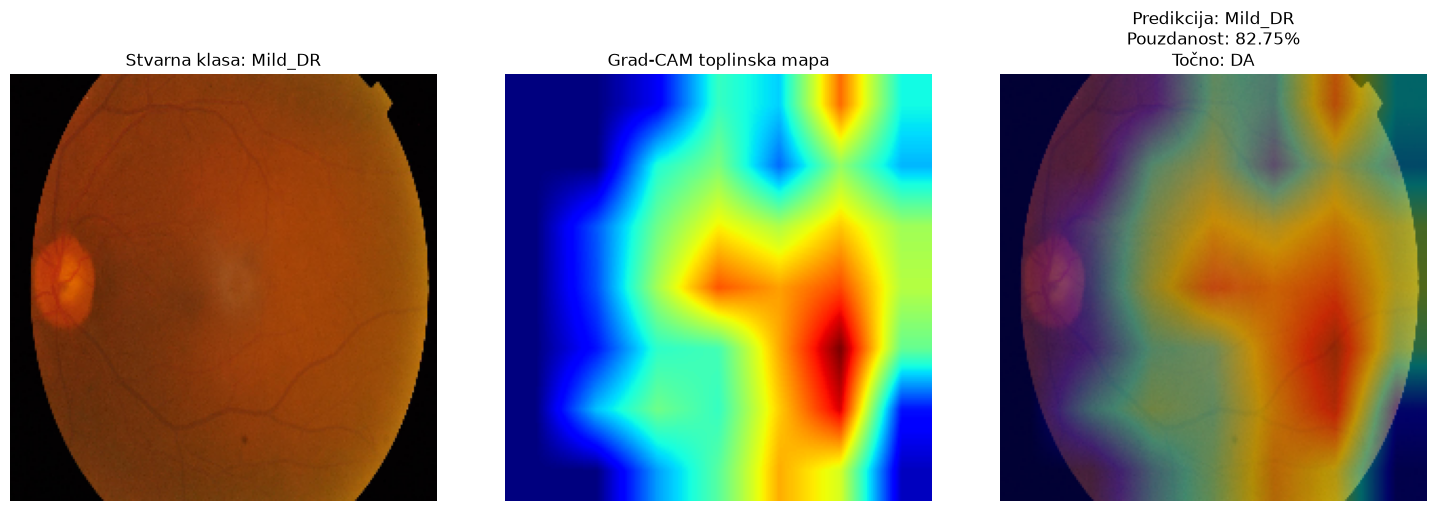

Mild_DR → Mild_DR (82.75%)


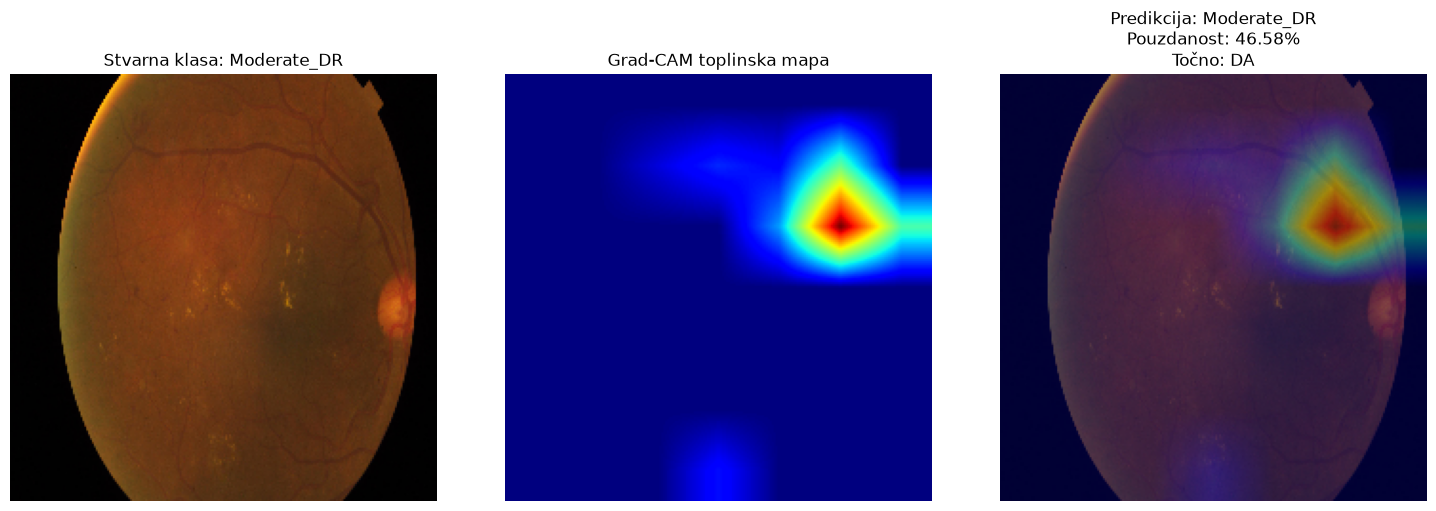

Moderate_DR → Moderate_DR (46.58%)


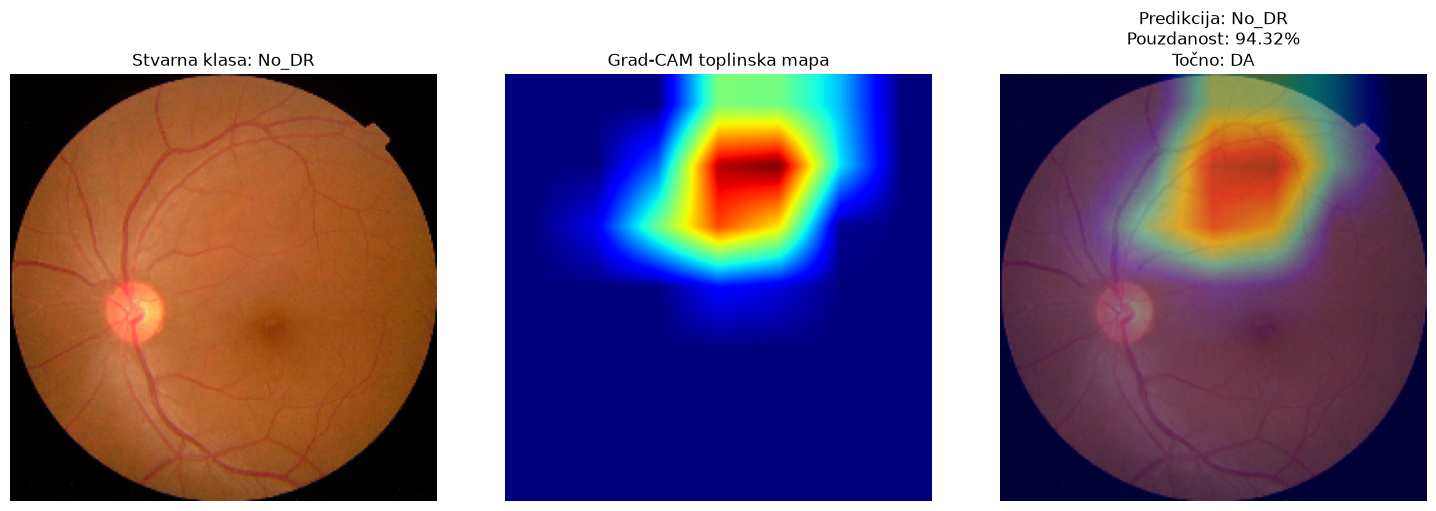

No_DR → No_DR (94.32%)


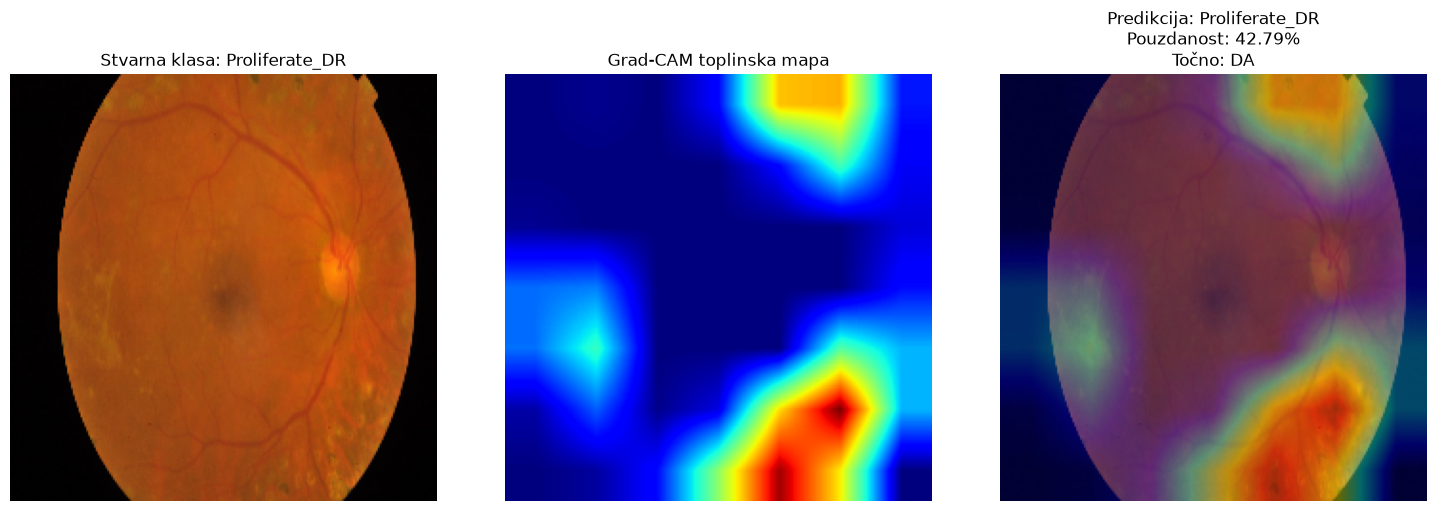

Proliferate_DR → Proliferate_DR (42.79%)


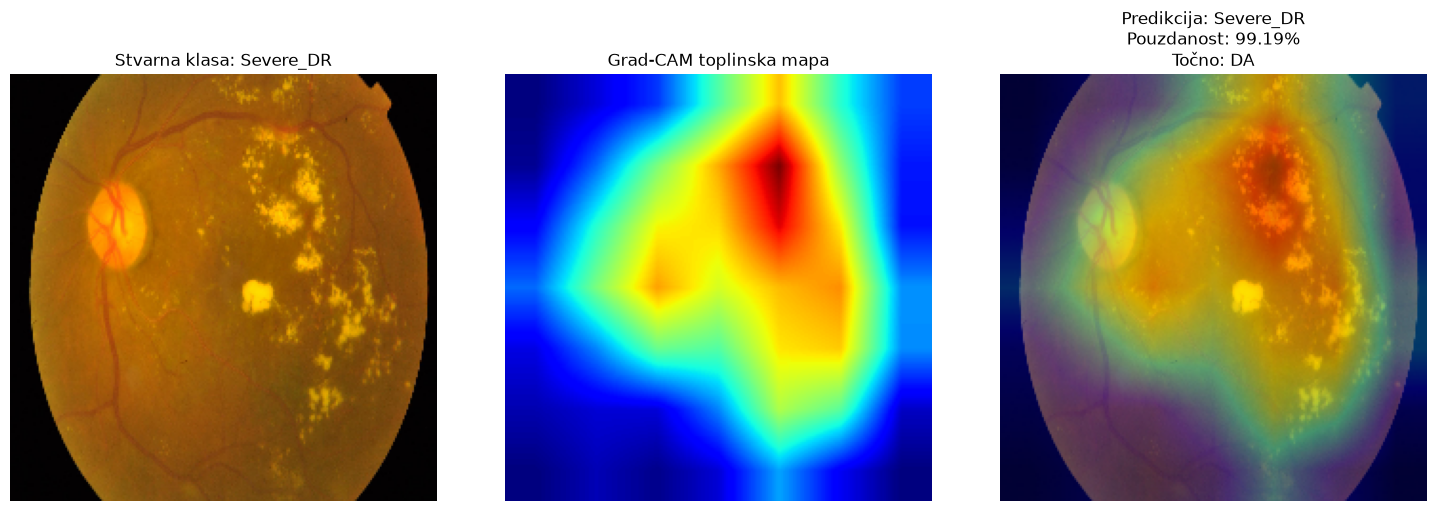

Severe_DR → Severe_DR (99.19%)


In [13]:
OUTPUT_DIR = "../Results/GradCAM/all_classes"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TEST_PATH = "../Dataset"

image_extensions = (".jpg", ".jpeg", ".png")

results = []

for true_class in class_names:
    class_folder = os.path.join(TEST_PATH, true_class)

    image_files = [
        file_name
        for file_name in os.listdir(class_folder)
        if file_name.lower().endswith(image_extensions)
    ]

    if not image_files:
        print(f"Nema slika u klasi: {true_class}")
        continue

    # Uzimamo prvu sliku iz klase
    image_path = os.path.join(
        class_folder,
        image_files[0]
    )

    original_img, img_batch = load_image_for_model(
        image_path
    )

    heatmap, predictions, predicted_index = (
        make_gradcam_heatmap(
            img_batch=img_batch,
            model=model,
            last_conv_layer_name="top_conv"
        )
    )

    predicted_class = class_names[predicted_index]
    confidence = float(
        predictions[0][predicted_index]
    )

    original_uint8 = np.clip(
        original_img,
        0,
        255
    ).astype(np.uint8)

    heatmap_resized = cv2.resize(
        heatmap,
        (
            original_uint8.shape[1],
            original_uint8.shape[0]
        )
    )

    heatmap_uint8 = np.uint8(
        255 * heatmap_resized
    )

    heatmap_colored = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    heatmap_colored = cv2.cvtColor(
        heatmap_colored,
        cv2.COLOR_BGR2RGB
    )

    superimposed_img = cv2.addWeighted(
        original_uint8,
        0.6,
        heatmap_colored,
        0.4,
        0
    )

    is_correct = true_class == predicted_class

    output_filename = (
        f"{true_class}_pred_{predicted_class}.png"
    )

    output_path = os.path.join(
        OUTPUT_DIR,
        output_filename
    )

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(original_uint8)
    plt.title(f"Stvarna klasa: {true_class}")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title("Grad-CAM toplinska mapa")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(superimposed_img)
    plt.title(
        f"Predikcija: {predicted_class}\n"
        f"Pouzdanost: {confidence:.2%}\n"
        f"Točno: {'DA' if is_correct else 'NE'}"
    )
    plt.axis("off")

    plt.tight_layout()

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    results.append({
        "stvarna_klasa": true_class,
        "predvidena_klasa": predicted_class,
        "pouzdanost": confidence,
        "tocna_predikcija": is_correct,
        "slika": image_files[0],
        "spremljeno_u": output_path
    })

    print(
        f"{true_class} → {predicted_class} "
        f"({confidence:.2%})"
    )

In [14]:
import pandas as pd

results_df = pd.DataFrame(results)

results_df

,stvarna_klasa,predvidena_klasa,pouzdanost,tocna_predikcija,slika,spremljeno_u
0,Mild_DR,Mild_DR,0.827542,True,0024cdab0c1e.png,../Results/GradCAM/all_classes\Mild_DR_pred_Mi...
1,Moderate_DR,Moderate_DR,0.465778,True,000c1434d8d7.png,../Results/GradCAM/all_classes\Moderate_DR_pre...
2,No_DR,No_DR,0.943162,True,002c21358ce6.png,../Results/GradCAM/all_classes\No_DR_pred_No_D...
3,Proliferate_DR,Proliferate_DR,0.427932,True,001639a390f0.png,../Results/GradCAM/all_classes\Proliferate_DR_...
4,Severe_DR,Severe_DR,0.991850,True,0104b032c141.png,../Results/GradCAM/all_classes\Severe_DR_pred_...


In [15]:
results_csv_path = os.path.join(
    OUTPUT_DIR,
    "gradcam_results.csv"
)

results_df.to_csv(
    results_csv_path,
    index=False,
    encoding="utf-8-sig"
)

print("Tablica spremljena u:", results_csv_path)

Tablica spremljena u: ../Results/GradCAM/all_classes\gradcam_results.csv
